Saved 3D orbit plot -> test_orbit_NFW_host_3D.png
Saved radius-vs-time plot -> test_orbit_NFW_host_R_t.png


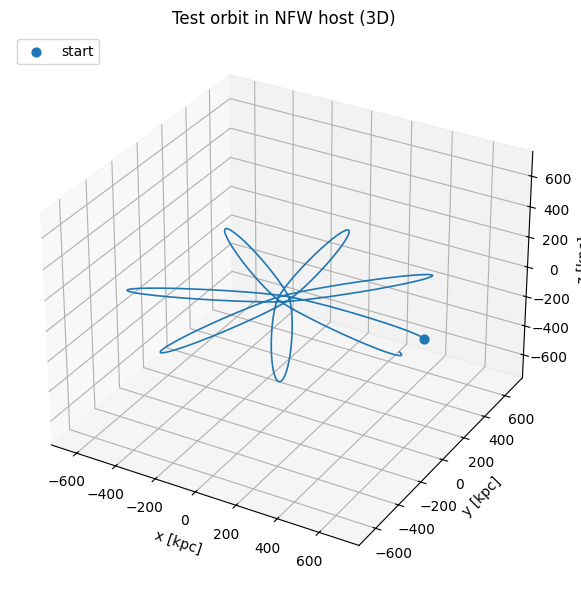

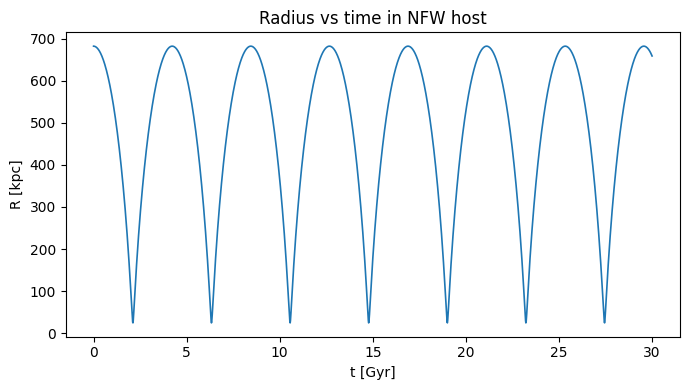

In [ ]:
#!/usr/bin/env python3
"""
Test orbit in an analytic NFW host halo (galpy, 3D plot, no astropy.units)

- Host halo is modeled as an NFW potential with (Mvir, c)
- Subhalo is treated as a test particle (no dynamical friction)
- Initial conditions are given in cylindrical coords (R, vR, vT, z, vz, phi)
- Integrates the orbit for a specified time in Gyr
- Produces:
    1) 3D orbit plot (x-y-z, host-centered)
    2) Radius vs time plot

Install:
    pip install galpy matplotlib numpy
"""

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from galpy.potential import NFWPotential
from galpy.orbit import Orbit

# ==========================
# CONFIGURATION
# ==========================

# ---- Host halo parameters (your validation host) ----
# NFWPotential(mvir=...) expects mvir in units of 1e12 Msun
LOG10_MVIR_MSUN = 13.5           # Mvir = 10^13.5 Msun
M_VIR_1E12 = 10**(LOG10_MVIR_MSUN - 12.0)  # in 1e12 Msun units
C_HOST = 6.5                     # concentration

# ---- galpy units (dimensionless) ----
# Interpret:
#   ro_unit = 1 kpc
#   vo_unit = 220 km/s
RO = 1.0      # length unit in galpy
VO = 220.0    # velocity unit in galpy (km/s)

# conversion from galpy time units to Gyr:
# 1 km/s * 1 Gyr ≈ 1.022712 kpc
KPC_PER_GYR_PER_KMS = 1.022712
RO_KPC  = 1.0          # 1 galpy length unit = 1 kpc
VO_KMS  = VO           # 1 galpy vel unit   = 220 km/s
T_UNIT_GYR = RO_KPC / (VO_KMS * KPC_PER_GYR_PER_KMS)  # ≈ 0.00445 Gyr

# ---- Initial orbit conditions (physical, then mapped to galpy) ----
# Example: start at R ~ 0.7 Rvir with small tangential velocity
R_VIR_KPC = 974.407
R0_KPC    = 0.7 * R_VIR_KPC     # starting radius
z0_KPC    = 0.0
phi0_RAD  = 0.0

vR0_KMS   = 0.0                 # ~apocenter
vT0_KMS   = 33.1515             # your ~33 km/s
vz0_KMS   = 0.0

# ---- Integration parameters ----
T_MAX_GYR = 10.0                # total integration time in Gyr
N_STEPS   = 2001                # number of steps

# ---- Output ----
PLOT_PREFIX = "test_orbit_NFW_host"
SHOW_FIGS   = True


# ==========================
# SETUP: host potential & orbit
# ==========================

def make_host_potential():
    """
    Create NFW host halo potential (dimensionless galpy units).
    """
    pot = NFWPotential(
        mvir=M_VIR_1E12,   # in units of 1e12 Msun
        conc=C_HOST,
        ro=RO,
        vo=VO
    )
    return pot


def make_orbit():
    """
    Create a galpy Orbit object using the global config.
    We convert physical values [kpc, km/s] to galpy units.
    """
    R0_g  = R0_KPC / RO_KPC
    z0_g  = z0_KPC / RO_KPC
    vR0_g = vR0_KMS / VO_KMS
    vT0_g = vT0_KMS / VO_KMS
    vz0_g = vz0_KMS / VO_KMS
    phi0  = phi0_RAD

    o = Orbit(vxvv=[R0_g, vR0_g, vT0_g, z0_g, vz0_g, phi0],
              ro=RO, vo=VO)
    return o


def integrate_orbit(o, pot):
    """
    Integrate orbit for T_MAX_GYR (in physical Gyr) using galpy units.

    Returns:
        t_galpy : (N,) array of times in galpy units
        t_Gyr   : (N,) array of times in Gyr (for plotting)
    """
    # Convert physical time span T_MAX_GYR [Gyr] to galpy units
    tmax_galpy = T_MAX_GYR / T_UNIT_GYR
    t_galpy = np.linspace(0.0, tmax_galpy, N_STEPS)

    o.integrate(t_galpy, pot)

    t_Gyr = t_galpy * T_UNIT_GYR
    return t_galpy, t_Gyr


# ==========================
# PLOTTING
# ==========================

def set_equal_3d(ax):
    """
    Make 3D axes have equal scale (so orbits aren't stretched).
    """
    x_limits = ax.get_xlim3d()
    y_limits = ax.get_ylim3d()
    z_limits = ax.get_zlim3d()

    x_range = x_limits[1] - x_limits[0]
    y_range = y_limits[1] - y_limits[0]
    z_range = z_limits[1] - z_limits[0]
    max_range = max(x_range, y_range, z_range)

    x_middle = 0.5 * (x_limits[0] + x_limits[1])
    y_middle = 0.5 * (y_limits[0] + y_limits[1])
    z_middle = 0.5 * (z_limits[0] + z_limits[1])

    half = 0.5 * max_range
    ax.set_xlim3d(x_middle - half, x_middle + half)
    ax.set_ylim3d(y_middle - half, y_middle + half)
    ax.set_zlim3d(z_middle - half, z_middle + half)


def plot_3d_orbit(o, t_galpy):
    """
    Plot the orbit in 3D (x, y, z) in kpc.
    """
    x = o.x(t_galpy) * RO_KPC
    y = o.y(t_galpy) * RO_KPC
    z = o.z(t_galpy) * RO_KPC

    fig = plt.figure(figsize=(7, 6))
    ax = fig.add_subplot(111, projection="3d")

    ax.plot(x, y, z, lw=1.2)
    ax.scatter([x[0]], [y[0]], [z[0]], marker="o", s=40, label="start")

    ax.set_xlabel("x [kpc]")
    ax.set_ylabel("y [kpc]")
    ax.set_zlabel("z [kpc]")
    ax.set_title("Test orbit in NFW host (3D)")
    set_equal_3d(ax)
    ax.legend(loc="upper left")

    plt.tight_layout()
    fname = f"{PLOT_PREFIX}_3D.png"
    plt.savefig(fname, dpi=200)
    print(f"Saved 3D orbit plot -> {fname}")


def plot_radius_vs_time(o, t_galpy, t_Gyr):
    """
    Plot orbital radius R(t) vs time in kpc and Gyr.
    """
    R = o.R(t_galpy) * RO_KPC

    plt.figure(figsize=(7, 4))
    plt.plot(t_Gyr, R, lw=1.2)
    plt.xlabel("t [Gyr]")
    plt.ylabel("R [kpc]")
    plt.title("Radius vs time in NFW host")
    plt.tight_layout()
    fname = f"{PLOT_PREFIX}_R_t.png"
    plt.savefig(fname, dpi=200)
    print(f"Saved radius-vs-time plot -> {fname}")


# ==========================
# MAIN
# ==========================

def main():
    pot = make_host_potential()
    orb = make_orbit()
    t_galpy, t_Gyr = integrate_orbit(orb, pot)

    plot_3d_orbit(orb, t_galpy)
    plot_radius_vs_time(orb, t_galpy, t_Gyr)

    if SHOW_FIGS:
        plt.show()
    else:
        plt.close('all')


if __name__ == "__main__":
    main()

Saved 3D orbit plot -> test_orbit_NFW_host_3D.png
Saved radius-vs-time plot -> test_orbit_NFW_host_R_t.png


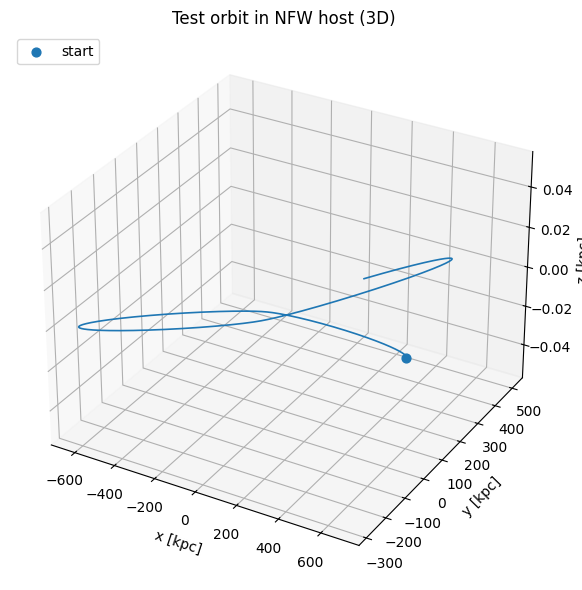

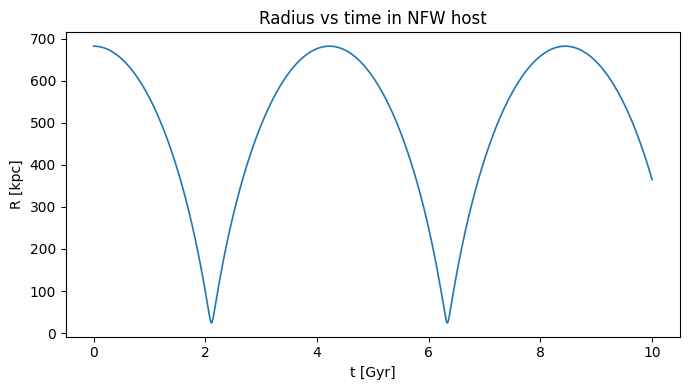

In [ ]:
#!/usr/bin/env python3
"""
Test orbit in an analytic NFW host halo (galpy, 3D plot, no astropy.units)

- No user-defined functions
- RO = 8 kpc (galpy default scaling)
"""

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from galpy.potential import NFWPotential
from galpy.orbit import Orbit

# ==========================
# CONFIGURATION
# ==========================

# ---- Host halo parameters ----
LOG10_MVIR_MSUN = 13.5
M_VIR_1E12 = 10 ** (LOG10_MVIR_MSUN - 12.0)
C_HOST = 6.5

# ---- galpy scaling ----
RO = 1.0
VO = 1.0

# Conversion from galpy time units to Gyr
KPC_PER_GYR_PER_KMS = 1.022712
RO_KPC = RO
VO_KMS = VO
T_UNIT_GYR = RO_KPC / (VO_KMS * KPC_PER_GYR_PER_KMS)

# ---- Initial orbit conditions ----
R_VIR_KPC = 974.407
R0_KPC = 0.7 * R_VIR_KPC
z0_KPC = 0.0
phi0_RAD = 0.0

vR0_KMS = 0.0
vT0_KMS = 33.1515
vz0_KMS = 0.0

# ---- Integration parameters ----
T_MAX_GYR = 10.0
N_STEPS = 2001

# ---- Output ----
PLOT_PREFIX = "test_orbit_NFW_host"
SHOW_FIGS = True

# ==========================
# HOST POTENTIAL
# ==========================

pot = NFWPotential(
    mvir=M_VIR_1E12,
    conc=C_HOST,
    ro=RO,
    vo=VO
)

# ==========================
# ORBIT SETUP
# ==========================

R0_g = R0_KPC / RO_KPC
z0_g = z0_KPC / RO_KPC
vR0_g = vR0_KMS / VO_KMS
vT0_g = vT0_KMS / VO_KMS
vz0_g = vz0_KMS / VO_KMS
phi0 = phi0_RAD

orb = Orbit(
    vxvv=[R0_g, vR0_g, vT0_g, z0_g, vz0_g, phi0],
    ro=RO,
    vo=VO
)

# ==========================
# INTEGRATION
# ==========================

tmax_galpy = T_MAX_GYR / T_UNIT_GYR
t_galpy = np.linspace(0.0, tmax_galpy, N_STEPS)

orb.integrate(t_galpy, pot)

t_Gyr = t_galpy * T_UNIT_GYR

# ==========================
# 3D ORBIT PLOT
# ==========================

x = orb.x(t_galpy) * RO_KPC
y = orb.y(t_galpy) * RO_KPC
z = orb.z(t_galpy) * RO_KPC

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")

ax.plot(x, y, z, lw=1.2)
ax.scatter([x[0]], [y[0]], [z[0]], marker="o", s=40, label="start")

ax.set_xlabel("x [kpc]")
ax.set_ylabel("y [kpc]")
ax.set_zlabel("z [kpc]")
ax.set_title("Test orbit in NFW host (3D)")

ax.legend(loc="upper left")

plt.tight_layout()
fname_3d = f"{PLOT_PREFIX}_3D.png"
plt.savefig(fname_3d, dpi=200)
print(f"Saved 3D orbit plot -> {fname_3d}")

# ==========================
# RADIUS VS TIME
# ==========================

R = orb.R(t_galpy) * RO_KPC

plt.figure(figsize=(7, 4))
plt.plot(t_Gyr, R, lw=1.2)
plt.xlabel("t [Gyr]")
plt.ylabel("R [kpc]")
plt.title("Radius vs time in NFW host")

plt.tight_layout()
fname_rt = f"{PLOT_PREFIX}_R_t.png"
plt.savefig(fname_rt, dpi=200)
print(f"Saved radius-vs-time plot -> {fname_rt}")

if SHOW_FIGS:
    plt.show()
else:
    plt.close("all")

In [4]:
x_predict=orb.x(t_galpy) * RO_KPC
y_predict=orb.y(t_galpy) * RO_KPC
z_predict=orb.z(t_galpy) * RO_KPC

print(x_predict)
print(y_predict)
print(z_predict)

[682.0849     682.08192429 682.07299711 ... 216.60313376 215.00855934
 213.40687738]
[0.00000000e+00 1.69521930e-01 3.39042381e-01 ... 2.99204015e+02
 2.97535179e+02 2.95856507e+02]
[0. 0. 0. ... 0. 0. 0.]
